# Phase 4 · 위치 인코딩 — '몇 번째'인지 알려주기 🔢

웹 챕터 **"위치 인코딩"** 과 짝을 이루는 실습입니다.
웹 실험실에서 위치를 껐다 켰다면, 여기서는 **벡터 덧셈**과 **사인·코사인 위치 인코딩**을 직접 계산합니다.

준비물: `pip install -r requirements.txt`

> 🤖 **AI 튜터** — 아래 셀을 실행하면 웹앱처럼 화면 오른쪽 아래에 🤖 버튼이 생깁니다.
> 버튼을 누르면 채팅창이 열리고, 어디를 스크롤해도 그 자리에 떠 있어요. 막히면 언제든 질문하세요.
> (로컬 Ollama 필요 — 꺼져 있으면 켜는 방법이 안내되고, 튜터 없이도 학습에는 지장 없습니다.)

In [ ]:
# 🤖 AI 튜터 — 실행하면 오른쪽 아래에 🤖 버튼이 떠요
from tutor import chat

chat('ch4')

## 1. 같은 단어, 다른 순서

"나 너 좋아해" 와 "너 나 좋아해" — 단어는 같지만 뜻은 정반대입니다.
간단한 2D 단어 임베딩과, 자리(슬롯)마다 다른 위치 벡터를 준비합니다. (웹 실험실과 같은 값)

In [1]:
import numpy as np

WORD = {'나': np.array([1.0, 0.0]),
        '너': np.array([0.0, 1.0]),
        '좋아해': np.array([0.5, 0.5])}

# 슬롯 1·2·3 의 위치 벡터 (교육용 단순 값)
POS = [np.array([0.0, 0.1]), np.array([0.5, 0.6]), np.array([1.0, 0.2])]

order_A = ['나', '너', '좋아해']   # 내가 너를 좋아해
order_B = ['너', '나', '좋아해']   # 네가 나를 좋아해

## 2. 최종 벡터 = 단어 임베딩 + 위치 벡터

자리마다 위치 벡터를 **더합니다**. 더하기라 차원(숫자 개수)은 그대로예요.

In [2]:
def encode(order, use_pos=True):
    out = []
    for i, w in enumerate(order):
        vec = WORD[w] + (POS[i] if use_pos else 0)
        out.append(vec)
    return np.array(out)

print('순서 A (위치 켜짐):')
for w, v in zip(order_A, encode(order_A)):
    print(f'  {w}: {np.round(v, 2)}')

순서 A (위치 켜짐):
  나: [1.  0.1]
  너: [0.5 1.6]
  좋아해: [1.5 0.7]


## 3. 위치가 없으면 두 순서를 구분 못 한다

위치를 끄면(use_pos=False), 두 순서는 **같은 벡터들의 집합**이라 구분할 수 없습니다.
위치를 켜면 슬롯마다 값이 달라져 순서가 살아납니다.

In [3]:
no_pos_A = encode(order_A, use_pos=False)
no_pos_B = encode(order_B, use_pos=False)
# 순서만 다를 뿐 '집합'은 동일 → 정렬하면 똑같음
same_set = np.allclose(np.sort(no_pos_A, axis=0), np.sort(no_pos_B, axis=0))
print('위치 없이 두 순서가 같은 벡터 집합인가? →', same_set)

with_A = encode(order_A, use_pos=True)
with_B = encode(order_B, use_pos=True)
same_set2 = np.allclose(np.sort(with_A, axis=0), np.sort(with_B, axis=0))
print('위치를 켜면 같은 집합인가?           →', same_set2, '(달라짐 → 구분 가능!)')

위치 없이 두 순서가 같은 벡터 집합인가? → True
위치를 켜면 같은 집합인가?           → False (달라짐 → 구분 가능!)


## 4. 진짜 방식: 사인·코사인 위치 인코딩

원래 트랜스포머 논문은 위치 벡터를 **사인·코사인**으로 만듭니다.
차원마다 파동의 주기를 다르게 해서, **위치마다 겹치지 않는 고유한 조합**을 만들어요.

In [4]:
def positional_encoding(num_pos, d_model):
    pe = np.zeros((num_pos, d_model))
    for pos in range(num_pos):
        for i in range(d_model):
            angle = pos / (10000 ** (2 * (i // 2) / d_model))
            pe[pos, i] = np.sin(angle) if i % 2 == 0 else np.cos(angle)
    return pe

pe = positional_encoding(16, 8)
print('위치 0 의 인코딩:', np.round(pe[0], 2))
print('위치 1 의 인코딩:', np.round(pe[1], 2))
print('모양(위치 x 차원):', pe.shape)

위치 0 의 인코딩: [0. 1. 0. 1. 0. 1. 0. 1.]
위치 1 의 인코딩: [0.84 0.54 0.1  1.   0.01 1.   0.   1.  ]
모양(위치 x 차원): (16, 8)


## 5. 위치 인코딩 히트맵

가로=차원, 세로=위치. 위치마다 줄무늬 패턴이 **모두 다른 것**이 보이나요? 그게 '고유한 위치 지문'입니다.

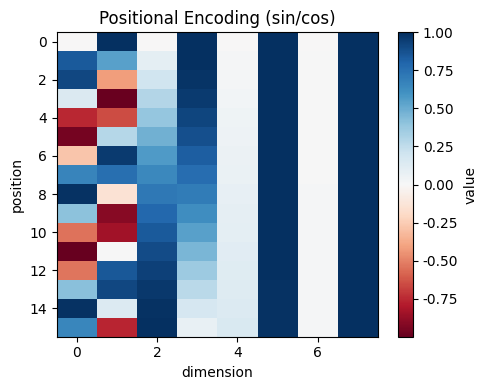

In [5]:
import matplotlib.pyplot as plt
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(5, 4))
plt.imshow(pe, aspect='auto', cmap='RdBu')
plt.xlabel('dimension'); plt.ylabel('position')
plt.colorbar(label='value'); plt.title('Positional Encoding (sin/cos)')
plt.tight_layout(); plt.show()

## 6. 직접 해보기 ✏️

단어 임베딩 `(2, 1)` 에 위치 벡터 `(0.5, 0.3)` 을 더하면? (웹 StepQuiz 와 같은 문제)

In [6]:
word = np.array([2.0, 1.0])
pos  = np.array([0.5, 0.3])
final = word + pos
print('최종 벡터:', final)

assert np.allclose(final, [2.5, 1.3]), '성분끼리 더하세요!'
print('✅ (2.5, 1.3) — 자리마다 위치가 달라 최종 벡터가 달라집니다.')

최종 벡터: [2.5 1.3]
✅ (2.5, 1.3) — 자리마다 위치가 달라 최종 벡터가 달라집니다.


---
이제 각 토큰 벡터에 **뜻 + 위치**가 모두 담겼습니다. 입력 준비 끝!
다음 챕터(ch5 어텐션의 직관)부터 단어들이 드디어 **서로를 참고**하기 시작합니다. 👀